In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create sparse design matrix X with most entries zero
np.random.seed(42)
N, P = 100, 20  # 100 samples, 20 features

# Sparse matrix: 90% zeros
X_sparse = np.random.binomial(1, 0.1, size=(N, P)) * np.random.randn(N, P)

# True sparse coefficients
true_beta = np.zeros(P)
true_beta[[0, 4, 9]] = [2.0, -1.0, 1.5]

# Generate response with noise
y_sparse = X_sparse @ true_beta + np.random.randn(N) * 0.3
X_sparse.shape, y_sparse.shape

((100, 20), (100,))

In [2]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.linear_model import LassoCV

lasso_cv_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('lasso', LassoCV(cv=5))
])
lasso_cv_pipe.fit(X_sparse, y_sparse)
y_pred_lasso = lasso_cv_pipe.predict(X_sparse)
mse_lasso = mean_squared_error(y_sparse, y_pred_lasso)
r2_lasso = r2_score(y_sparse, y_pred_lasso)


coef_lasso = lasso_cv_pipe.named_steps['lasso'].coef_
zero_lasso = np.sum(np.abs(coef_lasso) < 1e-8)

# Adative Lasso regression pipeline
from jax_model_lib.jax_sklearn_adapter import JaxSparseRegressor
P = X_sparse.shape[1]  # = 20

def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        'log_gamma': np.zeros(G, dtype=float),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P].astype(float)
    }
pipe = Pipeline([
    ('scale', StandardScaler()),
    ('jax_model', JaxSparseRegressor(
    lam_prior='group',
    lik='normal',
    lam_prior_vars=get_group_vars(P)
))
])

pipe.fit(X_sparse, y_sparse)
y_pred_jax = pipe.predict(X_sparse)
mse_jax = mean_squared_error(y_sparse, y_pred_jax)
r2_jax = r2_score(y_sparse, y_pred_jax)

coef_jax = pipe.named_steps['jax_model'].get_coefficients()
zero_jax = np.sum(np.abs(coef_jax) < 1e-8)




In [3]:
print(f"Lasso Regression     MSE: {mse_lasso:.4f}, R²: {r2_lasso:.4f}")
print(f"JAX Sparse Regressor MSE: {mse_jax:.4f}, R²: {r2_jax:.4f}")

print(f"Lasso shrank to 0:      {zero_lasso} / {len(coef_lasso)}")
print(f"JAX sparse shrank to 0: {zero_jax} / {len(coef_jax)}")

Lasso Regression     MSE: 0.0813, R²: 0.8316
JAX Sparse Regressor MSE: 0.0740, R²: 0.8467
Lasso shrank to 0:      13 / 20
JAX sparse shrank to 0: 2 / 20


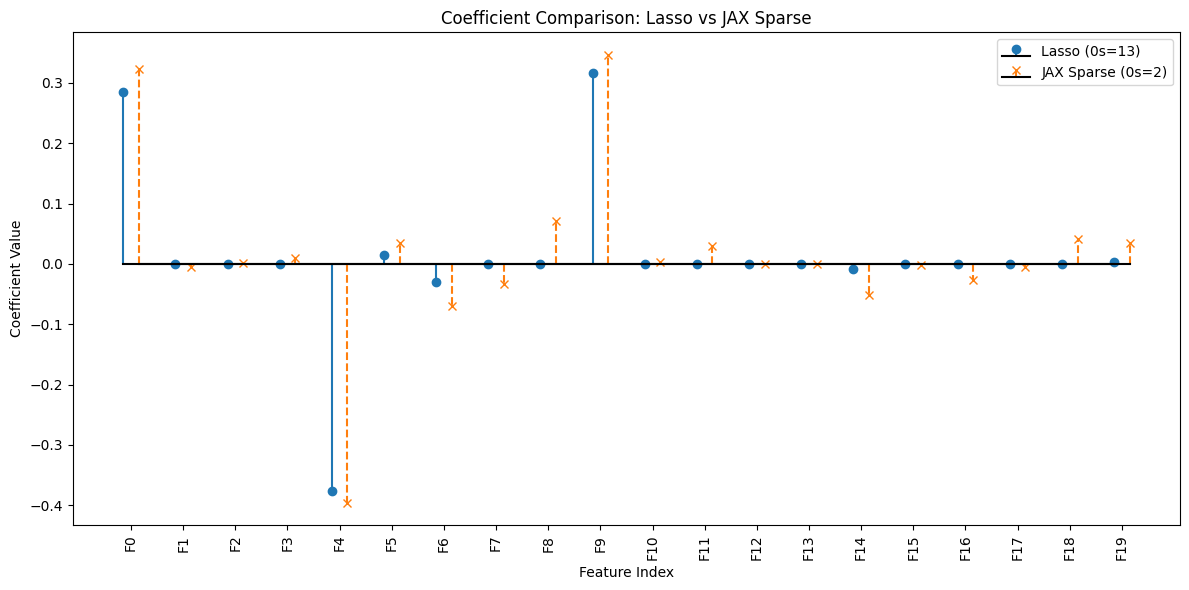

In [4]:
# Plot
x = np.arange(len(coef_lasso))
plt.figure(figsize=(12, 6))
plt.stem(x - 0.15, coef_lasso, linefmt='C0-', markerfmt='C0o', basefmt='k-', label=f'Lasso (0s={zero_lasso})')
plt.stem(x + 0.15, coef_jax, linefmt='C1--', markerfmt='C1x', basefmt='k-', label=f'JAX Sparse (0s={zero_jax})')
plt.xticks(x, [f"F{i}" for i in x], rotation=90)
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Coefficient Comparison: Lasso vs JAX Sparse")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from jax_model_lib.jax_sklearn_adapter import JaxSparseRegressor
import jax.numpy as jnp


# Prepare synthetic data
N, P = 80, 20
X = np.random.randn(N, P)
true_beta = np.zeros(P)
true_beta[:4] = [2.0, -1.0, 1.5, -1.2]
y = X @ true_beta + np.random.randn(N) * 0.5
y_binary = (y > np.median(y))
y_count = np.random.poisson(lam=np.exp(np.clip(X[:, 0], 0, 4)))

# Helper
def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        'log_gamma': np.zeros(G, dtype=float),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P]
    }

# Dummy custom functions
def custom_mse(vv, Xb, yb):
    preds = Xb @ vv['beta'] + vv['beta0']
    r = preds - yb
    loss = jnp.sum(r**2)
    grad = {
        'beta': 2 * Xb.T @ r,
        'beta0': 2 * jnp.sum(r),
        'lam': jnp.zeros_like(vv['lam']),
        'sigma2': jnp.array([0.0])
    }
    return loss, grad

def dummy_prior(x, pv, mod):
    x = jnp.atleast_1d(x)
    loss = jnp.sum(x**2)
    grad = {'lam': 2 * x}
    return loss, grad

def dummy_prox(vv, tau, lam, lr): return vv  # No-op prox

# Parameter grid (selectively representative, not exhaustive)
cases = [
    {'lam_prior': 'adaptive', 'lik': 'normal'},
    {'lam_prior': 'group', 'lik': 'bernoulli', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'poisson', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'adaptive', 'lik': 'none', 'custom_nll_grad': custom_mse, 'lam_prior_vars': {}},
    {'lam_prior': 'adaptive', 'lik': 'normal', 'custom_prior': dummy_prior, 'lam_prior_vars': {}},
    {'lam_prior': 'adaptive', 'lik': 'nb', 'custom_prior': dummy_prior, 'lam_prior_vars': {}},
    {'lam_prior': 'group', 'lik': 'normal', 'custom_prox': dummy_prox, 'lam_prior_vars': get_group_vars(P)}
]

print("Testing parameter combinations:")
for i, case in enumerate(cases):
    try:
        y_target = {
            'normal': y,
            'none': y,
            'bernoulli': y_binary,
            'poisson': y_count
        }[case['lik']]

        model = JaxSparseRegressor(
            tau0=0.8,
            max_iters=10,
            lr_pre=0.01,
            mb_size=20,
            invlam=False,
            logprox=False,
            track=True,
            **case
        )

        pipe = Pipeline([
            ('scale', StandardScaler()),
            ('jax_model', model)
        ])

        pipe.fit(X, y_target)
        y_pred = pipe.predict(X)
        r2 = r2_score(y_target, y_pred)
        nonzero = np.sum(np.abs(pipe.named_steps['jax_model'].get_coefficients()) > 1e-8)
        print(f"Case {i+1}: lam_prior={case['lam_prior']}, lik={case['lik']}, R²={r2:.3f}, nonzero={nonzero}")
    except Exception as e:
        print(f"Case {i+1} failed: {str(e)}")

Testing parameter combinations:
Case 1: lam_prior=adaptive, lik=normal, R²=0.026, nonzero=16
Case 2: lam_prior=group, lik=bernoulli, R²=-0.022, nonzero=18
Case 3: lam_prior=group, lik=poisson, R²=0.108, nonzero=19
Case 4: lam_prior=adaptive, lik=none, R²=-0.002, nonzero=0
Case 5 failed: iteration over a 0-d array
Case 6 failed: 'nb'
Case 7: lam_prior=group, lik=normal, R²=0.026, nonzero=17


In [1]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from jax_model_lib.jax_sklearn_adapter import JaxSparseRegressor
from sklearn.compose import TransformedTargetRegressor
import traceback

N, P = 100, 20
X = np.random.randn(N, P)

true_beta = np.zeros(P)
true_beta[:5] = [3.0, -2.0, 1.5, 0.5, -1.0]

y_normal = X @ true_beta + np.random.randn(N)
y_binary = (y_normal > np.median(y_normal))
y_poisson = np.random.poisson(lam=np.exp(np.clip(X[:, 0], 0, 3)))
y_nb = y_poisson + np.random.negative_binomial(1, 0.5, size=N)
y_zinb = y_poisson.copy()
y_zinb[np.random.rand(N) < 0.3] = 0
y_cauchy = np.clip(X @ true_beta + np.random.standard_cauchy(size=N), -10, 10) #限制 cauchy 的尾部，避免 NaN case 6

def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        #'log_gamma': np.zeros(G, dtype=float),
        'log_gamma': np.zeros(G),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P]
    }

cases = [
    {'lam_prior': 'adaptive', 'lik': 'normal'},
    {'lam_prior': 'adaptive', 'lik': 'poisson'},
    {'lam_prior': 'adaptive', 'lik': 'bernoulli'},
    {'lam_prior': 'adaptive', 'lik': 'nb'},
    {'lam_prior': 'adaptive', 'lik': 'zinb'},
    {'lam_prior': 'adaptive', 'lik': 'zinb', 'lam_prior_vars': {}},
    {'lam_prior': 'adaptive', 'lik': 'cauchy'},
    {'lam_prior': 'group', 'lik': 'normal', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'poisson', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'bernoulli', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'nb', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'zinb', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'cauchy', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'hier', 'lik': 'normal'},
    {'lam_prior': 'hier', 'lik': 'poisson'},
    {'lam_prior': 'hier', 'lik': 'bernoulli'},
]

lik2y = {
    'normal': y_normal,
    'poisson': y_poisson,
    'bernoulli': y_binary,
    'nb': y_nb,
    'zinb': y_zinb,
    'cauchy': y_cauchy
}

for i, case in enumerate(cases):
    try:
        y_target = lik2y[case['lik']]
        model = JaxSparseRegressor(
            **case
        )
        pipe = Pipeline([
            ('scale', StandardScaler()),
            ('model', model)
        ])

        pipe.fit(X, y_target)
        y_pred = pipe.predict(X)
        coef = pipe.named_steps['model'].get_coefficients()
        r2 = r2_score(y_target, y_pred)
        nz = np.sum(np.abs(coef) > 1e-6)
        print(f"Case {i+1}: lik={case['lik']:8s}, prior={case['lam_prior']:7s}, R²={r2:.3f}, nonzero={nz}")
    except Exception as e:
        print(f"Case {i+1} failed: {e}")
        traceback.print_exc()


Case 1: lik=normal  , prior=adaptive, R²=0.633, nonzero=17
Case 2: lik=poisson , prior=adaptive, R²=0.380, nonzero=17
Case 3: lik=bernoulli, prior=adaptive, R²=0.465, nonzero=16
Case 4: lik=nb      , prior=adaptive, R²=0.247, nonzero=17
Case 5: lik=zinb    , prior=adaptive, R²=0.232, nonzero=32
Case 6: lik=zinb    , prior=adaptive, R²=0.236, nonzero=31
Infinite cost!
Python 3.11.12 | packaged by conda-forge | (main, Apr 10 2025, 22:18:52) [Clang 18.1.8 ]
Type 'copyright', 'credits' or 'license' for more information
IPython 9.2.0 -- An enhanced Interactive Python. Type '?' for help.
Tip: You can use LaTeX or Unicode completion, `\alpha<tab>` will insert the α symbol.


Case 7: lik=cauchy  , prior=adaptive, R²=-0.051, nonzero=0
Case 8: lik=normal  , prior=group  , R²=0.643, nonzero=16
Case 9: lik=poisson , prior=group  , R²=0.398, nonzero=20
Case 10: lik=bernoulli, prior=group  , R²=0.454, nonzero=19
Case 11: lik=nb      , prior=group  , R²=0.208, nonzero=14
Case 12: lik=zinb    , prior=

Traceback (most recent call last):
  File "/var/folders/hg/426z78y129x_t04ws4ld063w0000gq/T/ipykernel_80586/3201676791.py", line 72, in <module>
    pipe.fit(X, y_target)
  File "/Users/u543860/miniforge3/envs/arm_jax_env/lib/python3.11/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/u543860/miniforge3/envs/arm_jax_env/lib/python3.11/site-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "/Users/u543860/AdaptiveLasso/jax_model_lib/jax_sklearn_adapter.py", line 83, in fit
    self.model_.fit(max_iters=self.max_iters, lr_pre=self.lr_pre, verbose=False)
  File "/Users/u543860/AdaptiveLasso/jax_model_lib/core.py", line 490, in fit
    cost_prior, grad_prior = self.eval_prior_grad(self.vv, self.tau0)
                             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/u543860/miniforge3/e

Gammat is: [[  0.   0.   1.   2.   3.   4.   5.   6.   7.   8.   9.  10.  11.  12.
   13.  14.  15.  16.  17.  18.]
 [  1.  19.  19.  20.  21.  22.  23.  24.  25.  26.  27.  28.  29.  30.
   31.  32.  33.  34.  35.  36.]
 [  2.  20.  37.  37.  38.  39.  40.  41.  42.  43.  44.  45.  46.  47.
   48.  49.  50.  51.  52.  53.]
 [  3.  21.  38.  54.  54.  55.  56.  57.  58.  59.  60.  61.  62.  63.
   64.  65.  66.  67.  68.  69.]
 [  4.  22.  39.  55.  70.  70.  71.  72.  73.  74.  75.  76.  77.  78.
   79.  80.  81.  82.  83.  84.]
 [  5.  23.  40.  56.  71.  85.  85.  86.  87.  88.  89.  90.  91.  92.
   93.  94.  95.  96.  97.  98.]
 [  6.  24.  41.  57.  72.  86.  99.  99. 100. 101. 102. 103. 104. 105.
  106. 107. 108. 109. 110. 111.]
 [  7.  25.  42.  58.  73.  87. 100. 112. 112. 113. 114. 115. 116. 117.
  118. 119. 120. 121. 122. 123.]
 [  8.  26.  43.  59.  74.  88. 101. 113. 124. 124. 125. 126. 127. 128.
  129. 130. 131. 132. 133. 134.]
 [  9.  27.  44.  60.  75.  89. 102. 114. 12

Traceback (most recent call last):
  File "/var/folders/hg/426z78y129x_t04ws4ld063w0000gq/T/ipykernel_80586/3201676791.py", line 72, in <module>
    pipe.fit(X, y_target)
  File "/Users/u543860/miniforge3/envs/arm_jax_env/lib/python3.11/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/u543860/miniforge3/envs/arm_jax_env/lib/python3.11/site-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "/Users/u543860/AdaptiveLasso/jax_model_lib/jax_sklearn_adapter.py", line 83, in fit
    self.model_.fit(max_iters=self.max_iters, lr_pre=self.lr_pre, verbose=False)
  File "/Users/u543860/AdaptiveLasso/jax_model_lib/core.py", line 490, in fit
    cost_prior, grad_prior = self.eval_prior_grad(self.vv, self.tau0)
                             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/u543860/miniforge3/e

In [7]:
# Test sklearn lasso
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

N, P = 100, 20
X = np.random.randn(N, P)

true_beta = np.zeros(P)
true_beta[:5] = [3.0, -2.0, 1.5, 0.5, -1.0]

y_normal = X @ true_beta + np.random.randn(N)

cases = [
    {'lam_prior': 'adaptive', 'lik': 'normal'},
]

lik2y = {
    'normal': y_normal,
}

for i, case in enumerate(cases):
    try:
        y_target = lik2y[case['lik']]
        pipe = Pipeline([
            ('scale', StandardScaler()),
            ('lasso', LassoCV())
        ])
        pipe.fit(X, y_normal)
        y_pred = pipe.predict(X)
        r2 = r2_score(y_normal, y_pred)
        coef = pipe.named_steps['lasso'].coef_
        nz = np.sum(np.abs(coef) > 1e-6)
        print(f"Case {i+1}: lik={case['lik']:8s}, prior={case['lam_prior']:7s}, R²={r2:.3f}, nonzero={nz}")
    except Exception as e:
        print(f"Case {i+1} failed: {e}")


Case 1: lik=normal  , prior=adaptive, R²=0.955, nonzero=18


In [12]:
# Test our lasso without scaling
from jax_model_lib.jax_sklearn_adapter import JaxSparseRegressor
import numpy as np

# Example data
N, P = 100, 20
X = np.random.randn(N, P)
true_beta = np.zeros(P)
true_beta[:5] = [3.0, -2.0, 1.5, 0.5, -1.0]
y = X @ true_beta + np.random.randn(N)


try:
    model = JaxSparseRegressor(lam_prior='adaptive', lik='normal')
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('model', model)
    ])
    pipe.fit(X, y)
    y_pred = pipe.predict(X)
    print("Success! R2:", np.corrcoef(y, y_pred)[0,1]**2)
except Exception as e:
    print("Case 1 failed:", e)

Success! R2: 0.898671575582562
